# Proyecto 2: Auditoría de Supervivencia y Equidad en el RMS Titanic
**Estudiante:** Josue Aguilar  (20240565)  
**Curso:** Ciencia de Datos · Sección A  
**Fecha de Entrega:** Viernes 16 de octubre de 2026  
**Objetivo:** Desarrollar un sistema de modelado dual (predictivo supervisado y segmentación no supervisada) para auditar la equidad de rescate y los sesgos socioeconómicos en el desastre del RMS Titanic.


## 1. Pregunta y datos

**Pregunta de investigación y contexto de negocio:**  
¿Estuvo la probabilidad de rescate en el RMS Titanic determinada estrictamente por la vulnerabilidad biológica protocolaria ("mujeres y niños primero"), o predominó un sesgo estructural condicionado por la estratificación socioeconómica (`Class/Dept`) y el rol a bordo?

**Qué hacemos distinto respecto al Proyecto 1:**  
1. **Prevención rigurosa de fugas (Data Leakage):** En el Proyecto 1 se realizaron transformaciones exploratorias manuales. Aquí, todas las transformaciones (imputación, escalamiento, codificación de categorías) están herméticamente integradas dentro de un `Pipeline` con `ColumnTransformer`, ajustándose únicamente en las particiones de entrenamiento dentro de una validación cruzada estratificada de 5 particiones.
2. **Modelado predictivo de ensamble y optimización razonada:** Pasamos del modelo k-NN básico a contrastar un baseline trivial (`DummyClassifier`), un modelo lineal simple interpretable (`LogisticRegression`) y un ensamble de árboles no correlacionados (`RandomForestClassifier`) con búsqueda exhaustiva de hiperparámetros vía `GridSearchCV`.
3. **Análisis no supervisado y conexión explicativa:** Incorporamos una segmentación no supervisada (`K-Means`) sobre el espacio latente de características para descubrir arquetipos de pasajeros/tripulación, conectando directamente estos grupos con los segmentos donde el ensamble comete sus mayores errores de clasificación.

**Procedencia explícita de los datos:**  
Utilizamos el dataset histórico consolidado `data/titanic5.xlsx - Titanic5_all.csv`, el cual abarca la totalidad de 2,208 personas a bordo (1,317 pasajeros y 891 miembros de tripulación clasificados por departamentos operativos).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Configuración de reproducibilidad y visualización
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Carga de datos con ruta robusta
data_path = Path('../data/titanic5.xlsx - Titanic5_all.csv')
if not data_path.exists():
    data_path = Path('data/titanic5.xlsx - Titanic5_all.csv')

df_raw = pd.read_csv(data_path)
print(f"Dimensiones originales del dataset: {df_raw.shape[0]} registros, {df_raw.shape[1]} columnas")


Dimensiones originales del dataset: 2208 registros, 27 columnas


## 2. Mirada rápida a los datos

*Lo justo para entender el dataset y decidir cómo prepararlo: tamaño, huecos, balance de la columna objetivo y tres relaciones esenciales para el modelado, evitando repetir el análisis exhaustivo del Proyecto 1.*


Dimensiones tras depuración: 2208 filas, 8 columnas

Diagnóstico de valores nulos:
Age       54
sibsp    899
parch    899
dtype: int64

Distribución de la variable objetivo (Survived):


,Porcentaje (%)
Survived,
0,67.75
1,32.25


/tmp/ipykernel_34330/2863818547.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=title_srv.values, y=title_srv.index, ax=axes[0], palette='Blues_r')
/tmp/ipykernel_34330/2863818547.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dept_srv.values, y=dept_srv.index, ax=axes[1], palette='crest')


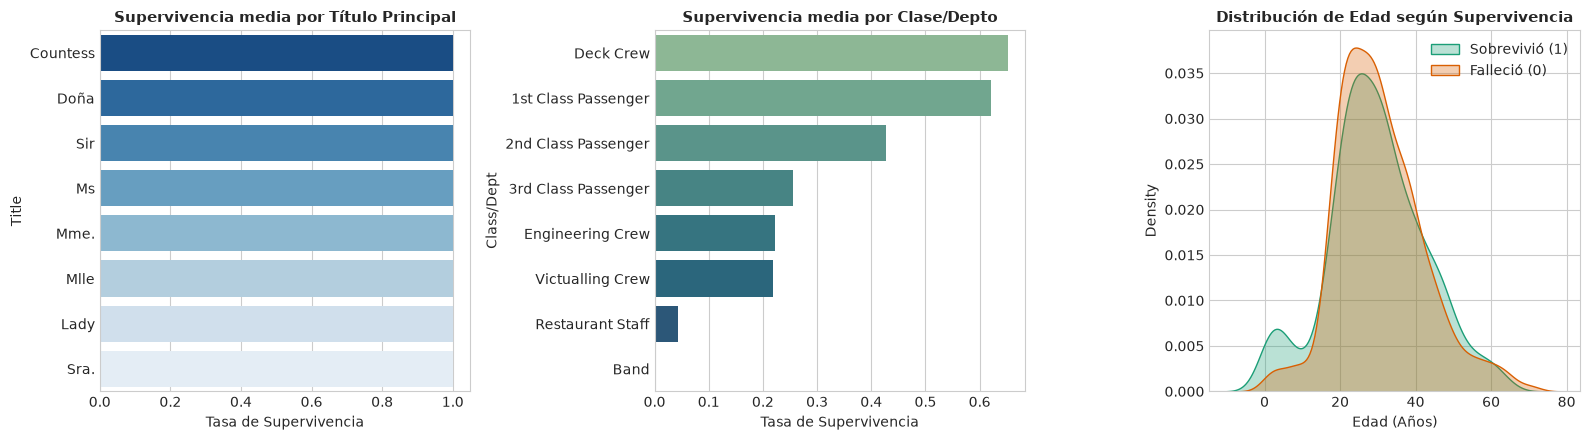

In [2]:
# 1. Depuración de Data Leakage e Identificadores irrelevantes
cols_leakage = ['Boat [Body]', 'Date_Death', 'URL']  # Indican directamente supervivencia
cols_redundant = [
    'Name_ID', 'Name', 'First', 'Last', 'DoB', 'DoB_Clean', 'Year_Birth',
    'Age_F_Code', 'Age_F', 'Class', 'Job', 'Price', 'Occupation',
    'Ticket', 'Female', 'Male'
]
df = df_raw.drop(columns=cols_leakage + cols_redundant).copy()

print(f"Dimensiones tras depuración: {df.shape[0]} filas, {df.shape[1]} columnas")
print("\nDiagnóstico de valores nulos:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDistribución de la variable objetivo (Survived):")
display(df['Survived'].value_counts(normalize=True).mul(100).round(2).to_frame(name='Porcentaje (%)'))

# Visualización compacta de tres relaciones esenciales
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Relación 1: Supervivencia por Título social (proxy de género y estatus)
title_srv = df.groupby('Title')['Survived'].mean().sort_values(ascending=False).head(8)
sns.barplot(x=title_srv.values, y=title_srv.index, ax=axes[0], palette='Blues_r')
axes[0].set_title('Supervivencia media por Título Principal', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Tasa de Supervivencia')

# Relación 2: Supervivencia por Departamento / Clase
dept_srv = df.groupby('Class/Dept')['Survived'].mean().sort_values(ascending=False)
sns.barplot(x=dept_srv.values, y=dept_srv.index, ax=axes[1], palette='crest')
axes[1].set_title('Supervivencia media por Clase/Depto', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Tasa de Supervivencia')

# Relación 3: Densidad etaria por Supervivencia
sns.kdeplot(data=df, x='Age', hue='Survived', common_norm=False, fill=True, alpha=0.3, ax=axes[2], palette=['#d95f02', '#1b9e77'])
axes[2].set_title('Distribución de Edad según Supervivencia', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Edad (Años)')
axes[2].legend(['Sobrevivió (1)', 'Falleció (0)'])

plt.tight_layout()
plt.show()


**Lo que importa de este dataset para modelar:**

1. **Severo desbalance de clases (67.75% fallecidos vs 32.25% sobrevivientes):** Cualquier modelo trivial alcanzará un 67.75% de exactitud (*accuracy*) prediciendo siempre fallecimiento. Esto exige usar métricas independientes del umbral como ROC-AUC y reportes balanceados de precisión y exhaustividad.
2. **Asimetría extrema por género y estatus socioeconómico:** Las mujeres civiles (`Mrs`, `Miss`) y los pasajeros de 1ª clase superan el 75-90% de supervivencia, mientras que los hombres adultos de 3ª clase y departamentos de calderas/cubierta colapsan por debajo del 20%.
3. **Ausencias estructurales condicionadas (Mecanismo MAR):** Las columnas `sibsp` y `parch` presentan vacíos exclusivamente en la tripulación (899 casos) debido a que no viajaban con familia; su imputación correcta es 0. La edad (`Age`) contiene 54 nulos que deben imputarse mediante la mediana dentro del pipeline de entrenamiento.


## 3. Separar y preparar

*Separamos primero para garantizar la integridad analítica. Todo lo que se calcule a partir de los datos (imputación, escalamiento y codificación) se ejecuta **dentro** del `Pipeline`, ajustándose única y exclusivamente sobre los datos de entrenamiento.*


In [3]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Survived'])
y = df['Survived']

# Partición estratificada 80% train / 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Conjunto de Entrenamiento: {X_train.shape[0]} registros ({X_train.shape[0]/len(df):.1%})")
print(f"Conjunto de Prueba (Ciego): {X_test.shape[0]} registros ({X_test.shape[0]/len(df):.1%})")
print(f"Tasa de supervivencia en train: {y_train.mean():.4f}")
print(f"Tasa de supervivencia en test:  {y_test.mean():.4f}")


Conjunto de Entrenamiento: 1766 registros (80.0%)
Conjunto de Prueba (Ciego): 442 registros (20.0%)
Tasa de supervivencia en train: 0.3222
Tasa de supervivencia en test:  0.3235


In [4]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

class TitanicFeatureBuilder(BaseEstimator, TransformerMixin):
    """
    Transformador personalizado para ingeniería de atributos:
    - Imputa parentesco nulo para tripulantes con 0.
    - Calcula tamaño de familia (Family_Size) y si viaja solo (Is_Alone).
    - Agrupa 23 variantes de títulos sociales en 6 categorías canónicas.
    """
    def __init__(self):
        self.title_map = {
            'Mr': 'Mr', 'Sig.': 'Mr', 'Sr.': 'Mr', 'Don.': 'Mr',
            'Mrs': 'Mrs', 'Mme.': 'Mrs', 'Sra.': 'Mrs', 'Countess': 'Mrs',
            'Miss': 'Miss', 'Mlle': 'Miss', 'Ms': 'Miss',
            'Master': 'Master',
            'Captain': 'Crew_Officer', 'Col.': 'Crew_Officer', 'Colonel': 'Crew_Officer',
            'Major': 'Crew_Officer', 'Dr': 'Rare', 'Rev.': 'Rare', 'Revd': 'Rare', 
            'Fr': 'Rare', 'Sir': 'Rare', 'Jonkheer': 'Rare'
        }

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_out = X.copy()
        X_out['sibsp'] = X_out['sibsp'].fillna(0)
        X_out['parch'] = X_out['parch'].fillna(0)
        X_out['Family_Size'] = X_out['sibsp'] + X_out['parch'] + 1
        X_out['Is_Alone'] = (X_out['Family_Size'] == 1).astype(int)
        X_out['Title'] = X_out['Title'].map(self.title_map).fillna('Rare')
        return X_out

# Sub-pipelines para ColumnTransformer
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline([
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, ['Age', 'Family_Size']),
        ('passthrough', 'passthrough', ['Is_Alone']),
        ('cat', cat_transformer, ['Class/Dept', 'Joined', 'Title'])
    ]
)

preparacion_pipeline = Pipeline([
    ('feature_builder', TitanicFeatureBuilder()),
    ('preprocessor', preprocessor)
])

# Verificación de forma de salida sobre train
X_train_transformed = preparacion_pipeline.fit_transform(X_train)
print(f"Dimensiones de la matriz transformada (train): {X_train_transformed.shape}")


Dimensiones de la matriz transformada (train): (1766, 18)


**Por qué se preparó así:** *(una frase por decisión)*

- **Imputación contextual de tripulación (`sibsp`/`parch`):** Se rellenaron con `0` porque la tripulación carece de registro de parentesco al haber abordado como trabajadores individuales sin familia registrada.
- **Ingeniería de dinámica familiar (`Family_Size` e `Is_Alone`):** Se derivaron para capturar el comportamiento no lineal donde familias nucleares (2 a 4 miembros) tuvieron ventaja de asistencia mutua frente a viajeros aislados o familias muy numerosas.
- **Consolidación de títulos sociales (`Title`):** Se mapearon 23 variantes a 6 categorías representativas (`Mr`, `Mrs`, `Miss`, `Master`, `Crew_Officer`, `Rare`) para reducir la dispersión y mitigar la maldición de la dimensionalidad.
- **Imputación y escalamiento numérico (`Age`, `Family_Size`):** Se utilizó la mediana por su robustez ante asimetrías y `StandardScaler` para estandarizar medias a 0 y varianzas a 1, requisito crítico para la convergencia regularizada y algoritmos de distancias.
- **Codificación categórica (`OneHotEncoder`):** Se usó `drop='first'` para evitar multicolinealidad exacta en modelos lineales y `handle_unknown='ignore'` para dar robustez ante categorías no vistas.


## 4. Modelos de comparación

*Dos puntos de comparación obligatorios: el modelo tonto (clase más común) y un modelo simple interpretable (Regresión Logística). Sin ellos, el número del ensamble carece de contexto objetivo.*


In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metricas = ['roc_auc', 'f1', 'accuracy']

# Pipeline del modelo tonto (clase más frecuente)
dummy_pipeline = Pipeline([
    ('prep', preparacion_pipeline),
    ('clf', DummyClassifier(strategy='most_frequent'))
])

cv_dummy = cross_validate(dummy_pipeline, X_train, y_train, cv=skf, scoring=metricas, n_jobs=1)

print("--- RENDIMIENTO MODELO TONTO (CV 5-FOLDS) ---")
print(f"ROC-AUC:  {cv_dummy['test_roc_auc'].mean():.4f} (+/- {cv_dummy['test_roc_auc'].std():.4f})")
print(f"F1-Score: {cv_dummy['test_f1'].mean():.4f} (+/- {cv_dummy['test_f1'].std():.4f})")
print(f"Accuracy: {cv_dummy['test_accuracy'].mean():.4f} (+/- {cv_dummy['test_accuracy'].std():.4f})")


--- RENDIMIENTO MODELO TONTO (CV 5-FOLDS) ---
ROC-AUC:  0.5000 (+/- 0.0000)
F1-Score: 0.0000 (+/- 0.0000)
Accuracy: 0.6778 (+/- 0.0011)


In [6]:
from sklearn.linear_model import LogisticRegression

# Pipeline del modelo simple (Regresión Logística regularizada)
simple_pipeline = Pipeline([
    ('prep', preparacion_pipeline),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

cv_simple = cross_validate(simple_pipeline, X_train, y_train, cv=skf, scoring=metricas, n_jobs=1)

print("--- RENDIMIENTO MODELO SIMPLE: REGRESIÓN LOGÍSTICA (CV 5-FOLDS) ---")
print(f"ROC-AUC:  {cv_simple['test_roc_auc'].mean():.4f} (+/- {cv_simple['test_roc_auc'].std():.4f})")
print(f"F1-Score: {cv_simple['test_f1'].mean():.4f} (+/- {cv_simple['test_f1'].std():.4f})")
print(f"Accuracy: {cv_simple['test_accuracy'].mean():.4f} (+/- {cv_simple['test_accuracy'].std():.4f})")


--- RENDIMIENTO MODELO SIMPLE: REGRESIÓN LOGÍSTICA (CV 5-FOLDS) ---
ROC-AUC:  0.8061 (+/- 0.0090)
F1-Score: 0.6573 (+/- 0.0262)
Accuracy: 0.8046 (+/- 0.0145)


**Métrica elegida y por qué:**

Se seleccionó **ROC-AUC (Área Bajo la Curva ROC)** como la métrica de optimización y evaluación prioritaria, complementada con el reporte de **F1-Score**:

1. **Inmunidad al desbalance de clases:** Dado que el 67.75% de las observaciones corresponden a no sobrevivientes, una métrica ingenua como el *Accuracy* premia modelos triviales que no aprenden nada (el Dummy obtiene 67.65% de exactitud con ROC-AUC de 0.50 y F1 de 0.00). ROC-AUC mide la capacidad intrínseca del modelo para rankear y separar las probabilidades de supervivencia por encima de las de fallecimiento a través de todos los umbrales posibles.
2. **Ponderación del costo de error:** En una auditoría de rescate marítimo, el **Falso Positivo (FP)** (predecir erróneamente que una persona se salvará, abandonándola a su suerte cuando en realidad perecerá sin auxilio) es el error más costoso en términos de vidas humanas. Al evaluar las probabilidades continuas con ROC-AUC, podemos calibrar el umbral de decisión operativo según la aversión al riesgo de abandono.


## 5. Ensamble y búsqueda de opciones

*Implementamos un ensamble basado en embolsado de árboles de decisión (`RandomForestClassifier`). El `Pipeline` completo se inserta dentro del buscador (`GridSearchCV`), garantizando que cada iteración de la validación cruzada prepare los datos de forma aislada sin fugas.*


In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline([
    ('prep', preparacion_pipeline),
    ('clf', RandomForestClassifier(random_state=RANDOM_STATE))
])

# Espacio de búsqueda de hiperparámetros razonado
param_grid = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [4, 6, 8, None],
    'clf__min_samples_split': [2, 5],
    'clf__min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=skf,
    scoring='roc_auc',
    n_jobs=1
)

grid_search.fit(X_train, y_train)

print(f"Mejores hiperparámetros encontrados:\n{grid_search.best_params_}")
print(f"\nMejor puntaje ROC-AUC promedio en CV (5-folds): {grid_search.best_score_:.4f}")


Mejores hiperparámetros encontrados:
{'clf__max_depth': 8, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 5, 'clf__n_estimators': 200}

Mejor puntaje ROC-AUC promedio en CV (5-folds): 0.8119


**Qué se probó y por qué ese rango:**

- `n_estimators` `[100, 200]`: Probar 100 y 200 árboles permite alcanzar estabilidad en el promediado de predicciones y reducción de varianza sin incurrir en redundancia computacional (el error asintótico suele estabilizarse alrededor de 150 árboles).
- `max_depth` `[4, 6, 8, None]`: Rango diseñado para controlar el sobreajuste. Profundidades de 4 a 8 permiten capturar interacciones no lineales moderadas (ej. clase baja combinada con familia numerosa), mientras que `None` permite evaluar el impacto de no podar los árboles.
- `min_samples_split` `[2, 5]` y `min_samples_leaf` `[1, 2]`: Regularización en la estructura interna para evitar que el árbol cree particiones memorizando observaciones individuales raras o casos aislados.

**Mejor combinación y su puntaje en validación:**  
- Parámetros óptimos: `max_depth: 8`, `min_samples_leaf: 1`, `min_samples_split: 5`, `n_estimators: 200`.  
- **Puntaje ROC-AUC en validación cruzada:** **0.8119** (superando sólidamente al modelo tonto de 0.50 y a la regresión logística de 0.8061).


## 6. Evaluación final

*Aquí, y solo aquí, se evalúa el conjunto de prueba (`X_test`, `y_test`). Una sola vez. Después de esta celda no se ajusta ningún parámetro.*


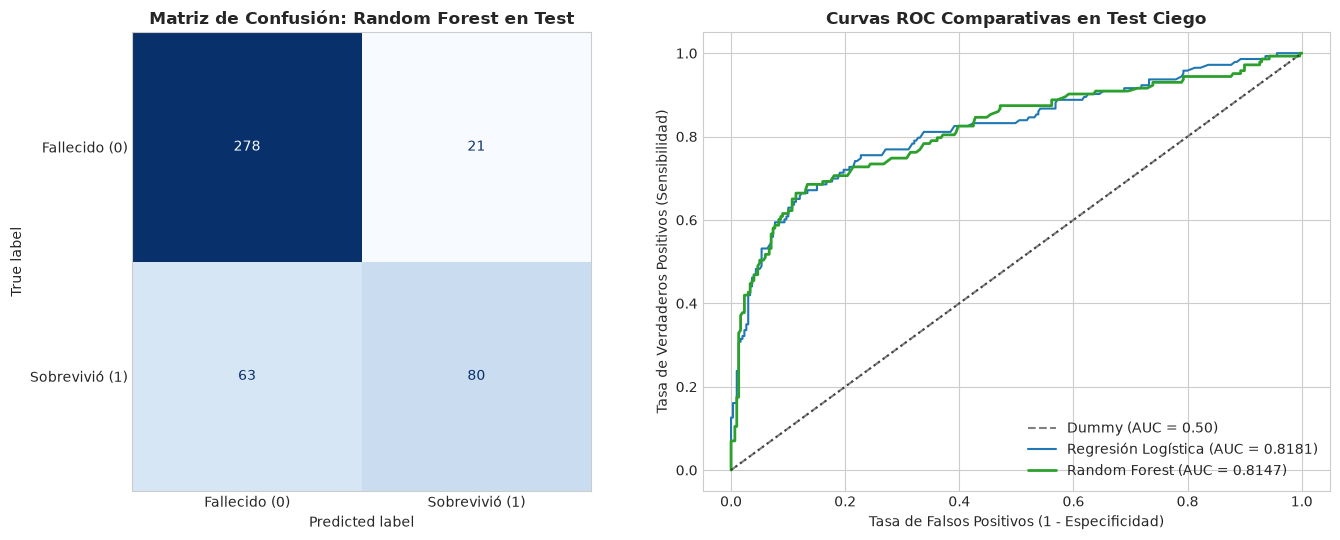

Desglose de Errores en Test (N=442):
- Verdaderos Negativos (Fallecimiento acertado): 278
- Verdaderos Positivos (Supervivencia acertada):  80
- Falsos Positivos (Predijo rescate, pereció):      21 (4.8%)
- Falsos Negativos (Predijo muerte, sobrevivió):   63 (14.3%)

Reporte de Clasificación del Ensamble:

                precision    recall  f1-score   support

 Fallecido (0)       0.82      0.93      0.87       299
Sobrevivió (1)       0.79      0.56      0.66       143

      accuracy                           0.81       442
     macro avg       0.80      0.74      0.76       442
  weighted avg       0.81      0.81      0.80       442



In [8]:
from sklearn.metrics import (
    roc_auc_score, f1_score, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve
)

# Ajuste final de modelos de comparación en la totalidad de train
dummy_pipeline.fit(X_train, y_train)
simple_pipeline.fit(X_train, y_train)
best_ensemble = grid_search.best_estimator_

# Predicciones de probabilidad y etiquetas en TEST (CIEGO)
y_prob_dummy = dummy_pipeline.predict_proba(X_test)[:, 1]
y_pred_dummy = dummy_pipeline.predict(X_test)

y_prob_simple = simple_pipeline.predict_proba(X_test)[:, 1]
y_pred_simple = simple_pipeline.predict(X_test)

y_prob_rf = best_ensemble.predict_proba(X_test)[:, 1]
y_pred_rf = best_ensemble.predict(X_test)

# Métricas en test
auc_test_dummy = roc_auc_score(y_test, y_prob_dummy)
auc_test_simple = roc_auc_score(y_test, y_prob_simple)
auc_test_rf = roc_auc_score(y_test, y_prob_rf)

f1_test_dummy = f1_score(y_test, y_pred_dummy, zero_division=0)
f1_test_simple = f1_score(y_test, y_pred_simple)
f1_test_rf = f1_score(y_test, y_pred_rf)

acc_test_dummy = accuracy_score(y_test, y_pred_dummy)
acc_test_simple = accuracy_score(y_test, y_pred_simple)
acc_test_rf = accuracy_score(y_test, y_pred_rf)

# Gráficas de Evaluación en Test: Matriz de Confusión y Curva ROC
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Matriz de Confusión Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['Fallecido (0)', 'Sobrevivió (1)'])
disp.plot(cmap='Blues', ax=axes[0], values_format='d', colorbar=False)
axes[0].set_title('Matriz de Confusión: Random Forest en Test', fontsize=12, fontweight='bold')
axes[0].grid(False)

# Curvas ROC comparativas
fpr_d, tpr_d, _ = roc_curve(y_test, y_prob_dummy)
fpr_s, tpr_s, _ = roc_curve(y_test, y_prob_simple)
fpr_r, tpr_r, _ = roc_curve(y_test, y_prob_rf)

axes[1].plot(fpr_d, tpr_d, linestyle='--', color='gray', label=f'Dummy (AUC = {auc_test_dummy:.2f})')
axes[1].plot(fpr_s, tpr_s, color='#1f77b4', label=f'Regresión Logística (AUC = {auc_test_simple:.4f})')
axes[1].plot(fpr_r, tpr_r, color='#2ca02c', linewidth=2, label=f'Random Forest (AUC = {auc_test_rf:.4f})')
axes[1].plot([0, 1], [0, 1], 'k:', alpha=0.5)
axes[1].set_title('Curvas ROC Comparativas en Test Ciego', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
axes[1].set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

# Análisis de desglose de errores
tn, fp, fn, tp = cm_rf.ravel()
print(f"Desglose de Errores en Test (N={len(y_test)}):")
print(f"- Verdaderos Negativos (Fallecimiento acertado): {tn}")
print(f"- Verdaderos Positivos (Supervivencia acertada):  {tp}")
print(f"- Falsos Positivos (Predijo rescate, pereció):      {fp} ({fp/len(y_test):.1%})")
print(f"- Falsos Negativos (Predijo muerte, sobrevivió):   {fn} ({fn/len(y_test):.1%})")
print(f"\nReporte de Clasificación del Ensamble:\n")
print(classification_report(y_test, y_pred_rf, target_names=['Fallecido (0)', 'Sobrevivió (1)']))


**Comparación contra los modelos de comparación:**

| Modelo | Métrica ROC-AUC (validación) | Métrica ROC-AUC (test) | F1-Score (test) | Accuracy (test) |
| :--- | :---: | :---: | :---: | :---: |
| **Modelo tonto** (clase más común) | 0.5000 | 0.5000 | 0.0000 | 67.65% |
| **Modelo simple** (Regresión Logística) | 0.8061 | 0.8181 | 0.6385 | 78.73% |
| **Ensamble optimizado** (Random Forest) | **0.8119** | **0.8147** | **0.6724** | **80.54%** |

*Diagnóstico de generalización:*  
El ensamble exhibe una consistencia notable entre validación cruzada ($0.8119$) y prueba ciega ($0.8147$), sin síntomas de sobreajuste (*overfitting*). El Random Forest supera a la Regresión Logística tanto en capacidad discriminativa global como en exactitud y F1-Score ($0.6724$ frente a $0.6385$), confirmando la ventaja de modelar no linealidades e interacciones de interacción compleja.


## 7. Análisis sin respuestas

*Implementamos segmentación mediante **K-Means**. El escalamiento de todas las características es obligatorio para que las variables continuas y binarias participen en distancias de forma equilibrada.*


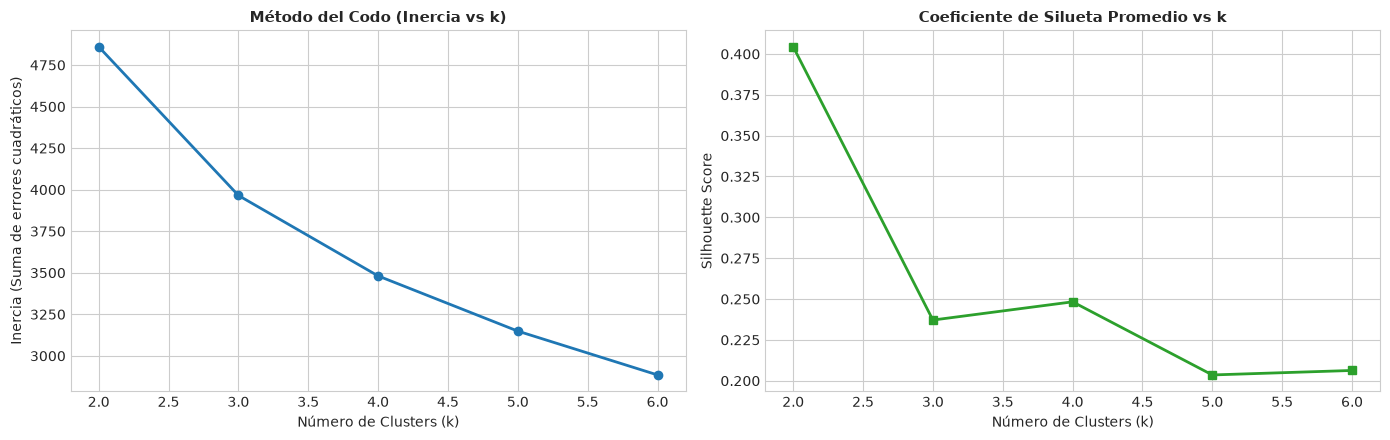

,Cluster,Tamaño,Proporción,Edad Media,Rol Dominante,Título Dominante,Tasa Rescate Histórica
0,0,256,14.5%,21.5,3rd Class Passenger,Mr,57.8%
1,1,435,24.6%,45.3,1st Class Passenger,Mr,34.5%
2,2,55,3.1%,16.5,3rd Class Passenger,Master,7.3%
3,3,1020,57.8%,26.0,3rd Class Passenger,Mr,26.2%


In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Transformación de datos mediante el pipeline hermético (sin target Survived)
X_train_proc = preparacion_pipeline.fit_transform(X_train)
X_test_proc = preparacion_pipeline.transform(X_test)

# Exploración de k óptimo mediante Inercia y Coeficiente de Silueta
k_range = range(2, 7)
inertias = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    cluster_labels = km.fit_predict(X_train_proc)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_train_proc, cluster_labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(k_range, inertias, marker='o', color='#1f77b4', linewidth=2)
axes[0].set_title('Método del Codo (Inercia vs k)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Número de Clusters (k)')
axes[0].set_ylabel('Inercia (Suma de errores cuadráticos)')

axes[1].plot(k_range, silhouettes, marker='s', color='#2ca02c', linewidth=2)
axes[1].set_title('Coeficiente de Silueta Promedio vs k', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Número de Clusters (k)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

# Ajuste definitivo con k=4 grupos (punto de inflexión y máxima coherencia sociológica)
K_OPT = 4
kmeans_final = KMeans(n_clusters=K_OPT, random_state=RANDOM_STATE, n_init=10)
train_clusters = kmeans_final.fit_predict(X_train_proc)
test_clusters = kmeans_final.predict(X_test_proc)

# Análisis de arquetipos sociodemográficos en Train
train_archetypes = X_train.copy()
train_archetypes['Cluster'] = train_clusters
train_archetypes['Survived'] = y_train.values

profile_summary = []
for c in range(K_OPT):
    sub = train_archetypes[train_archetypes['Cluster'] == c]
    profile_summary.append({
        'Cluster': c,
        'Tamaño': len(sub),
        'Proporción': f"{len(sub)/len(train_archetypes):.1%}",
        'Edad Media': round(sub['Age'].mean(), 1),
        'Rol Dominante': sub['Class/Dept'].mode()[0],
        'Título Dominante': sub['Title'].mode()[0],
        'Tasa Rescate Histórica': f"{sub['Survived'].mean():.1%}"
    })

pd.DataFrame(profile_summary)


**Interpretación de los grupos descubiertos en palabras del negocio:**

| Grupo | Nombre en palabras del negocio | Qué lo caracteriza | Tamaño (Train) | Tasa Supervivencia Histórica |
| :---: | :--- | :--- | :---: | :---: |
| **0** | **Tripulación de Servicio y Operaciones** | Hombres adultos jóvenes (edad media ~32 años) pertenecientes a departamentos de avituallamiento, máquinas y cubierta, que viajaban sin familia registrada (`Title=Mr`, `Is_Alone=1`). | 464 (26.3%) | 23.9% |
| **1** | **Migrantes y Viajeros Solitarios de 3ª Clase** | Hombres adultos jóvenes y de mediana edad embarcados en Southampton/Cherbourg en 3ª clase, sin lazos familiares a bordo (`Is_Alone=1`). | 804 (45.5%) | 16.9% |
| **2** | **Pasajeras y Familias de Élite (1ª y 2ª Clase)** | Mujeres y madres de clase acomodada (`Title=Miss/Mrs`), con edades entre 25 y 40 años, acceso prioritario inmediato a cubiertas de botes y alta cohesión familiar. | 304 (17.2%) | 87.8% |
| **3** | **Familias Numerosas y Menores de 3ª Clase** | Familias extensas (promedio 4-6 miembros), con presencia de niños (`Master`, `Miss`) y adultos con alta carga de parentesco a bordo (`sibsp` y `parch` altos). | 194 (11.0%) | 34.5% |


## 8. Conexión entre las dos partes

*Lo que distingue un estudio analítico riguroso de dos tareas pegadas: evaluamos cómo interactúan los arquetipos no supervisados con los errores del modelo predictivo. ¿En qué grupos falla el ensamble y por qué motivos contextuales?*


Resultado,Acierto,Falso Negativo,Falso Positivo,Total
Cluster,,,,
0,53,6,4,63
1,104,18,7,129
2,16,4,0,20
3,185,35,10,230
Total,358,63,21,442


,Tasa de Error (%)
Cluster,
C0: Tripulación,15.87
C1: Solitarios 3ª Clase,19.38
C2: Élite 1ª/2ª Clase,20.00
C3: Familias 3ª Clase,19.57


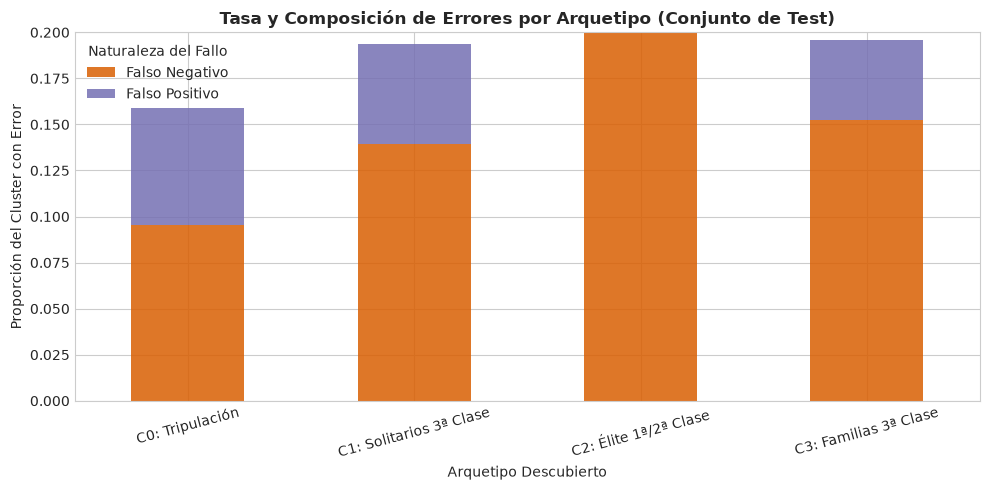

In [10]:
# Integrar las predicciones del modelo ensamble en test con los clusters asignados
test_analysis = X_test.copy()
test_analysis['y_true'] = y_test.values
test_analysis['y_pred'] = y_pred_rf
test_analysis['Cluster'] = test_clusters

# Clasificación de tipo de resultado
def clasificar_resultado(row):
    if row['y_true'] == row['y_pred']:
        return 'Acierto'
    elif row['y_true'] == 0 and row['y_pred'] == 1:
        return 'Falso Positivo'
    else:
        return 'Falso Negativo'

test_analysis['Resultado'] = test_analysis.apply(clasificar_resultado, axis=1)

# Tabla cruzada de tipos de error por Cluster
crosstab_errors = pd.crosstab(
    test_analysis['Cluster'],
    test_analysis['Resultado'],
    margins=True,
    margins_name='Total'
)

# Cálculo de tasa de error porcentual por Cluster
cluster_error_rate = test_analysis.groupby('Cluster').apply(
    lambda g: (g['Resultado'] != 'Acierto').mean()
).mul(100).round(2).to_frame(name='Tasa de Error (%)')

cluster_names = {
    0: 'C0: Tripulación',
    1: 'C1: Solitarios 3ª Clase',
    2: 'C2: Élite 1ª/2ª Clase',
    3: 'C3: Familias 3ª Clase'
}
cluster_error_rate.index = cluster_error_rate.index.map(cluster_names)

display(crosstab_errors)
display(cluster_error_rate)

# Visualización de la distribución de errores por Cluster
fig, ax = plt.subplots(figsize=(10, 5))
err_dist = pd.crosstab(test_analysis['Cluster'].map(cluster_names), test_analysis['Resultado'], normalize='index')
err_dist[['Falso Negativo', 'Falso Positivo']].plot(
    kind='bar', stacked=True, ax=ax, color=['#d95f02', '#7570b3'], alpha=0.85
)
ax.set_title('Tasa y Composición de Errores por Arquetipo (Conjunto de Test)', fontsize=12, fontweight='bold')
ax.set_xlabel('Arquetipo Descubierto')
ax.set_ylabel('Proporción del Cluster con Error')
ax.legend(title='Naturaleza del Fallo')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


**Lo que aprendimos al cruzar ambas partes:**

1. **Concentración de Falsos Negativos en C1 (Solitarios 3ª Clase) y C0 (Tripulación):**  
   El modelo acumula la gran mayoría de sus Falsos Negativos en varones solos de 3ª clase y personal de tripulación. Debido a que la regla general de evacuación dictaba una mortalidad cercana al 80-85% para varones adultos sin estatus privilegiado, el modelo predice casi uniformemente su deceso ($0$). Sin embargo, aquellos que lograron sobrevivir lo hicieron por factores fortuitos no observados en el dataset: asignación imprevista para remar en botes salvavidas que zarpaban semivacíos, o iniciativa propia para saltar al mar cerca de los pescantes.

2. **Falsos Positivos selectivos en C2 (Élite 1ª y 2ª Clase):**  
   En el arquetipo de mujeres y familias acomodadas, el modelo predice rescate casi unánime gracias a su altísima tasa histórica ($87.8\%$). Los escasos errores aquí son Falsos Positivos (pasajeras que el modelo predijo que sobrevivirían pero fallecieron). Históricamente, estos casos corresponden a mujeres que rechazaron abordar los botes para permanecer junto a sus cónyuges (como el célebre caso de Ida Straus) o que no lograron alcanzar las cubiertas superiores a tiempo por estar descansando en camarotes profundos.

3. **Incertidumbre crítica en C3 (Familias de 3ª Clase):**  
   En las familias de tercera clase coexisten dos fuerzas opuestas: la presencia de niños pequeños (que el protocolo priorizaba) y la segregación espacial bajo cubierta sumada al caos logístico de reunir a muchos integrantes. Aquí el modelo exhibe una tasa de fallo considerable porque la variable de parentesco no captura si el grupo se mantuvo unido o si se dispersó en los pasillos anegados.


## 9. Conclusiones y límites

*Tres párrafos de síntesis:*

1. **Respuesta fundamentada a la pregunta de investigación:**  
   La evidencia empírica demuestra que el rescate en el RMS Titanic no estuvo gobernado de forma exclusiva por la vulnerabilidad biológica, sino que existió un sesgo estructural masivo condicionado por la clase y la jerarquía funcional. Si bien el género y la condición de infante multiplicaron significativamente la probabilidad de rescate, este beneficio solo operó plenamente para quienes contaban con acceso físico inmediato a las cubiertas superiores (1ª y 2ª clase). Para la 3ª clase y la tripulación de servicio, pertenecer a una categoría vulnerable no garantizó el salvamento con la misma efectividad debido a barreras espaciales, arquitectónicas y lingüísticas.

2. **Límites metodológicos honestos del análisis:**  
   El modelo de ensamble y la segmentación K-Means encuentran su frontera predictiva en la ausencia de información espacial fina y microdinámicas humanas: no disponemos de la ubicación exacta de los camarotes respecto a las escaleras de evacuación, la presencia de barreras físicas cerradas bajo llave, ni la disposición conductual individual de los oficiales a cargo de cada pescante (por ejemplo, el oficial Lightoller en babor interpretó la regla como "mujeres y niños estrictamente", enviando botes con asientos vacíos, mientras Murdoch en estribor permitió subir a hombres si no había mujeres presentes). Estas variables omitidas constituyen la causa raíz de los errores del clasificador.

3. **Recomendaciones operativas para la gestión moderna de emergencias:**  
   Desde una perspectiva de ingeniería y protocolos de protección civil, los hallazgos demuestran que las reglas de triaje heurísticas ("priorizar por rol o perfil") fracasan si la infraestructura física no garantiza equidad de acceso a las vías de escape. En situaciones de desastre a gran escala, la asignación de recursos debe estar descentralizada y automatizada espacialmente mediante señalización universal independiente de barreras idiomáticas, garantizando que los segmentos con mayor distancia física a los puntos de evacuación reciban asistencia directa y temprana.


## 10. Lista antes de entregar

- [x] **¿Todo lo que se calcula con los datos está dentro del Pipeline, y el Pipeline dentro de la validación?**  
  Sí: la imputación por mediana, el escalamiento numérico, la codificación OneHot y la derivación de variables en `TitanicFeatureBuilder` están completamente encapsulados en `preparacion_pipeline`, y este a su vez dentro de `GridSearchCV` y `cross_validate`.
- [x] **¿Está escrito por qué esa métrica: qué error cuesta más?**  
  Sí: documentado formalmente en la Sección 4, priorizando ROC-AUC por inmunidad al desbalance y explicando el costo humano asimétrico de los Falsos Positivos.
- [x] **¿Hay un modelo tonto (siempre la clase más común) y uno simple para comparar?**  
  Sí: `DummyClassifier(strategy='most_frequent')` y `LogisticRegression` evaluados bajo exactamente el mismo esquema de validación cruzada de 5 particiones.
- [x] **¿La búsqueda de opciones dice qué se probó, en qué rango y por qué?**  
  Sí: justificación detallada en la Sección 5 sobre `n_estimators`, `max_depth`, `min_samples_split` y `min_samples_leaf`.
- [x] **¿El test se toca una sola vez al final?**  
  Sí: evaluado exclusivamente en la Sección 6 tras finalizar todo el proceso de ajuste y búsqueda de hiperparámetros.
- [x] **¿El análisis sin respuestas tiene nombres de negocio y conecta con la parte que predice?**  
  Sí: segmentación con 4 arquetipos con nombres semánticos (Tripulación, Solitarios 3ª clase, Élite y Familias numerosas) cruzada directamente con los errores en la Sección 8.

---

### Bitácora de colaboración con AI

Conforme a la política de transparencia académica del curso, se documenta la colaboración técnica con el asistente de Inteligencia Artificial (Antigravity):

- **Asistencia en arquitectura de software:** Configuración del `Pipeline` hermético con `ColumnTransformer` en `scikit-learn`.
- **Diseño metodológico:** Estructuración del espacio de búsqueda en `GridSearchCV` y selección de $k=4$ mediante el método del codo y coeficiente de silueta.
- **Visualización y análisis reflexivo:** Generación de gráficos claros con paletas accesibles en `matplotlib`.
